<a href="https://colab.research.google.com/github/rlaj0730-design/deep-learning-study/blob/main/ex04_BERTopic_%EA%B8%B0%EB%B0%98_%ED%85%8D%EC%8A%A4%ED%8A%B8_%EB%A7%88%EC%9D%B4%EB%8B%9D.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
# 구글 마운트
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
# 작업 경로 변경
%cd /content/drive/MyDrive/Colab Notebooks/딥러닝응용

/content/drive/MyDrive/Colab Notebooks/딥러닝응용


In [ ]:
!pip install -q transformers[torch] datasets

# transformers 설치
# datasets 공개데이터 셋을 쉽게 불러오고 사용할 수 있게 해주는 라이브러리

### 목표
- 사전학습이 되어있는 모델들만 활용해서 요약 -> 임베딩 -> 클러스터링 -> 감성분석을 포함하는 통합 분석 파이프라인 구현

### 시나리오
- 배경
  - 월간 50만 건 이상의 SNS 대화를 처리하는 기업용 분석 플랫폼
  - AI허브에서 제공하는 한국어 SNS 데이터를 기반으로 사용자의 대화 내용을 자동 탐지 및 분류 해야함
  - 긴 대화 로그에는 메타정보, 반복 발화, 잡음 등이 포함 되어있어서 핵심 주제 파악과 감성 분석이 어려움
  - 요약 -> 임베딩 -> 클러스터링 -> 감성분석의 통합 파이프라인으로 자동 인사이트 생성이 필요

#### AI hub - 한국어 SNS 데이터셋
- https://aihub.or.kr/aihubdata/data/view.do?currMenu=115&topMenu=100&aihubDataSe=realm&dataSetSn=114
- JSON 형식으로 제공됨, 각 대화에 메타정보와 발화(utterance) 리스트(body)가 포함
- 데이터셋이 방대해서 실습상 "미용과건강", "식음료", "일과직업"만 활용
  - 기존 라벨 : 개인관계, 미용과 건강, 상거래(쇼핑), 시사교육, 식음료, 여가생활, 일과직업, 주거와생활, 행사

In [ ]:
# unzip 명령으로 압축 해제
# 자동 완성(주피터에서는 tab) -> 코랩에서는 ctrl + space

# -q : quitly 조용히
# -u : update 최신으로
# -d : directory 경로 및 폴더명 지정
!unzip -q ./data/Korean\ SNS.zip -d ./data/Korean_SNS

replace ./data/Korean_SNS/Training/미용과건강.json? [y]es, [n]o, [A]ll, [N]one, [r]ename: 

In [ ]:
# 데이터 준비
# 필요한 라이브러리 불러오기
import json, os, re

# re : 정규표현식 사용을 위한 라이브러리

In [ ]:
train_dir = './data/Korean_SNS/Training/' # 약 36만건
val_dir = './data/Korean_SNS/Validation/' # 약 4만 5천건

# 라벨별로 200개만 사용하기 위해 제한
limit_per_label = 200

In [ ]:
# 모든 라벨 불러오기 전에 한 개 라벨만 불러와보기
temp_fname = os.listdir(train_dir)[0]
temp_path = os.path.join(train_dir, temp_fname)
temp_path

'./data/Korean_SNS/Training/미용과건강.json'

In [ ]:
# JSON 파일 불러오기
with open(temp_path, 'r', encoding = 'utf-8') as f:
  data = json.load(f)

In [ ]:
data.keys()

# header : 정보
# body에 대화가 포함

In [ ]:
len(sample_data['body'])

In [ ]:
# 첫 번째 대화 지정
sample_data = data['data'][0]

In [ ]:
# 3번 인덱스의 발화(텍스트) 가져오기
sample_data['body'][3]['utterance']

# 'utterance' : 발화, 언어학에서 사용하는 기본 언어 단위

In [ ]:
# 모든 발화를 연결해서 하나의 텍스트로 생성
sample_text = " ".join(t['utterance'] for t in sample_data['body'])
sample_text

In [ ]:
for t in sample_data['body']:
  print(t['utterance'], end = ' ')

In [ ]:
from tqdm.auto import tqdm # 반복문 진행 정도를 시각적으로 파악할 수 있게 해주는 도구

# 모든 json 데이터 불러오는 함수
def load_and_normalize(dir_path):
  """
  dir_path 내 모든 json 파일을 순회하면서 각 대화의 발화(utterance)를 하나의 문서(text)로 연결하는 함수
  parameter(dir_path) : str (json 파일들의 경로)
  return(corpus) : list (대화가 병합된 텍스트 리스트)
  """
  corpus = [] # 결과를 담을 리스트
  for fname in tqdm(os.listdir(dir_path), desc=f"Loading {dir_path}"):
    # 해당 폴더내 모든 파일의 이름을 가져와서 반복
    file_path = os.path.join(dir_path,fname)
    count = 0 # 라벨당 문서수 카운터 초기화

    with open(file_path,'r',encoding='utf-8') as f:
      dataset = json.load(f)

    for dialog in tqdm(dataset['data'],desc=f'전처리중 {fname}'):
      if count>= limit_per_label:
        # 라벨당 제한 초과 시 반복 종료
        break

      text = " ".join(body['utterance'] for body in dialog['body'])
      # 각 발화(body)의 'utterance'필드만 추출하여 공백으로 연결

      corpus.append(text) # 리스트 추가
      count += 1 # 문서 카운터 증가

  return corpus

In [ ]:
# 학습 및 검증 데이터셋 로드
train_corpus = load_and_normalize(train_dir)
val_corpus = load_and_normalize(val_dir)

In [ ]:
# 불러온 데이터 확인
print(f'train 문서 수 : {len(train_corpus)}')
print(f'val 문서 수 : {len(val_corpus)}')

# 발화 내용 확인
for i in range(3):
  print(f'[문서{i+1}] {train_corpus[i][:50]}... \n')

### 대화 요약(summarization)
- 요약을 앞서서 하는 이유
  - 문서 길이 절감 : 요약을 통해 핵심 내용만 남기면 후속 작업(임베딩, 토핑 모델링 등) 연산 속도를 높일 수 있음
  - 노이즈 제거 : 불필요한 대화(인사, 중복 발화 등)를 압축해서 중요한 주제어 비중을 높임
  - 토픽 명확화 : 긴 대화 데신 요약문을 사용해서 BERTopic이 더 뚜렷한 주제어를 학습 가능

In [ ]:
#! pip uninstall transformers

In [ ]:
!pip install -q "transformers<5.0.0"

In [ ]:
import transformers
print(transformers.__version__)

4.57.6


In [ ]:

from transformers import AutoTokenizer, AutoModelForSeq2SeqLM

tokenizer = AutoTokenizer.from_pretrained("psyche/KoT5-summarization")
model = AutoModelForSeq2SeqLM.from_pretrained("psyche/KoT5-summarization", device_map="auto")

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


model.safetensors:   0%|          | 0.00/1.19G [00:00<?, ?B/s]

### T5
- 우리가 사용할 요약 모델(KoT5) : https://huggingface.co/psyche/KoT5-summarization
- Text to Text Transfer Transformer
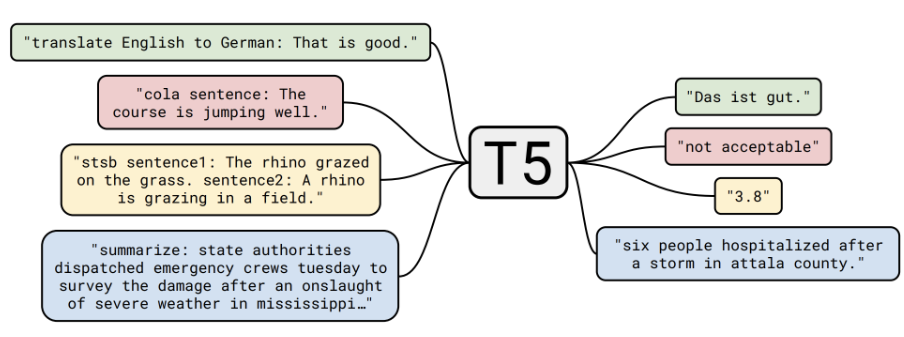

> #### 사전학습 정보 (Pre-training)
- **코퍼스**  
  - 위키백과, 신문기사 등 23개 출처에서 수집한 총 939 GB 원시 데이터 → 전처리 후 약 42 GB 말뭉치 사용
- **체크포인트**  
  - KoT5-Small: 6 layers, hidden_size=512, 60M 파라미터  
  - KoT5-Base: 12 layers, hidden_size=768, 220M 파라미터

> #### 파인튜닝(Fine-tuning)
- **데이터셋**  
  - AI-Hub “도서자료 요약” 데이터셋  
- **디코딩 설정**  
  - greedy decoding  
  - 최대 길이 `max_length=256`, `repetition_penalty=2.0` 적용
  - repetition_penalty : 같은 토큰이 반복적으로 나오면 penalty를 적용해서 해당 토큰의 logit을 낮춰줌 (값은 1.0 이상이며, 값이 클 수록 penalty를 세게 적용)

In [ ]:
# 라이브러리 불러오기 (버전 낮춰서)
# 데이터 불러오기
# 허깅페이스에서 직접 모델 불러오기(토크나이저, 모델)

In [3]:
import json, os, re

In [4]:
train_dir = './data/Korean_SNS/Training/' # 약 36만건
val_dir = './data/Korean_SNS/Validation/' # 약 4만 5천건

# 라벨별로 200개만 사용하기 위해 제한
limit_per_label = 200

In [5]:
from tqdm.auto import tqdm # 반복문 진행 정도를 시각적으로 파악할 수 있게 해주는 도구

# 모든 json 데이터 불러오는 함수
def load_and_normalize(dir_path):
  """
  dir_path 내 모든 json 파일을 순회하면서 각 대화의 발화(utterance)를 하나의 문서(text)로 연결하는 함수
  parameter(dir_path) : str (json 파일들의 경로)
  return(corpus) : list (대화가 병합된 텍스트 리스트)
  """
  corpus = [] # 결과를 담을 리스트
  for fname in tqdm(os.listdir(dir_path), desc=f"Loading {dir_path}"):
    # 해당 폴더내 모든 파일의 이름을 가져와서 반복
    file_path = os.path.join(dir_path,fname)
    count = 0 # 라벨당 문서수 카운터 초기화

    with open(file_path,'r',encoding='utf-8') as f:
      dataset = json.load(f)

    for dialog in tqdm(dataset['data'],desc=f'전처리중 {fname}'):
      if count>= limit_per_label:
        # 라벨당 제한 초과 시 반복 종료
        break

      text = " ".join(body['utterance'] for body in dialog['body'])
      # 각 발화(body)의 'utterance'필드만 추출하여 공백으로 연결

      corpus.append(text) # 리스트 추가
      count += 1 # 문서 카운터 증가

  return corpus

In [6]:
# 학습 및 검증 데이터셋 로드
train_corpus = load_and_normalize(train_dir)
val_corpus = load_and_normalize(val_dir)

Loading ./data/Korean_SNS/Training/:   0%|          | 0/3 [00:00<?, ?it/s]

전처리중 미용과건강.json:   0%|          | 0/99383 [00:00<?, ?it/s]

전처리중 식음료.json:   0%|          | 0/146620 [00:00<?, ?it/s]

전처리중 일과직업.json:   0%|          | 0/107976 [00:00<?, ?it/s]

Loading ./data/Korean_SNS/Validation/:   0%|          | 0/3 [00:00<?, ?it/s]

전처리중 일과직업.json:   0%|          | 0/13498 [00:00<?, ?it/s]

전처리중 식음료.json:   0%|          | 0/18328 [00:00<?, ?it/s]

전처리중 미용과건강.json:   0%|          | 0/12423 [00:00<?, ?it/s]

In [7]:
# 불러온 데이터 확인
print(f'train 문서 수 : {len(train_corpus)}')
print(f'val 문서 수 : {len(val_corpus)}')

# 발화 내용 확인(3개)
for i in range(3):
  print(f'[문서 {i+1}] {train_corpus[i][:50]}... \n')

train 문서 수 : 600
val 문서 수 : 600
[문서 1] 마니아프세여??? #@시스템#사진# 흙흙흙 아 개피곤 ㅋㅋ 님 괜찮아여? 왜 먹고 먹고 머... 

[문서 2] 구냥 기른거같은데... ㅋ켘캨ㅋㅋㅋ ㅋㅋㅋㅋㅋㅋ알지 뭔날린디 #@이름# 털을보면 관리를해서... 

[문서 3] 다자기랑먹느라찐디 아닌데요!! 평일에 9시에 저녁을먹눈데 당연히찌죠 아닌데요?! 데이트할때... 



In [8]:
# 버전 낮춰서 설치
!pip install -q "transformers<5.0.0"

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gradio 6.31.0 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.
diffusers 0.42.1 requires huggingface-hub<3.0,>=1.32.0, but you have huggingface-hub 0.36.2 which is incompatible.
gradio-client 2.7.2 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.


In [9]:
# 버전 확인, 5버전 미만이면 됨
import transformers
print(transformers.__version__)

4.57.6


In [10]:
# 허깅페이스에서 토크나이저, 모델 가져오기
from transformers import AutoTokenizer, AutoModelForSeq2SeqLM

tokenizer = AutoTokenizer.from_pretrained("psyche/KoT5-summarization")
model = AutoModelForSeq2SeqLM.from_pretrained("psyche/KoT5-summarization", device_map="auto")
# AutoModelForSeq2SeqLM : seq2seq 구조의 언어모델에 사용되는 도구

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


tokenizer_config.json: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

special_tokens_map.json: 0.00B [00:00, ?B/s]

config.json: 0.00B [00:00, ?B/s]

model.safetensors:   0%|          | 0.00/1.19G [00:00<?, ?B/s]

In [12]:
# GPU 사용 여부 확인
import torch

device = "cuda" if torch.cuda.is_available() else "cpu"
print(device)

cpu


In [13]:
# 모델을 불러올때 지정된 디바이스(일반적으로는 GPU사용함.)로 텐서를 이동
model = model.to(device)

In [15]:
# 샘플 텍스트로 요약 모델 테스트
sample_text = train_corpus[0]
print(sample_text)

마니아프세여??? #@시스템#사진# 흙흙흙 아 개피곤 ㅋㅋ 님 괜찮아여? 왜 먹고 먹고 머고만 햇는데 몸이 무겁지 걸은것도 별로 없는데 몰라여 응가싸서 그런가 고되다 똥싸서 몸무게 빠졋나 아삐건해 미틴ㅋㅋㅋㅋㅋㅋ 진짜 7-800그람 빠짐 나 몸이 너무 무거워서 몸무게 쟀는데 빠져서 놀랏어 너무 무서워


In [18]:
# 입력 텍스트 토큰화
inputs = tokenizer(
    text = sample_text, # 요약 대상 텍스트
    return_tensors = 'pt', # pytorch 텐서로 반환
    truncation = True, # 길이 초과 시 잘라내기
    max_length = 512 # 토큰 최대 길이 제한(T5 position embedding 크기가 512로 고정되어있음)
).to(device)

inputs

# 'input_ids' : 주어진 문장을 모델이 이해할 수 있는 정수 시퀀스 ID(토큰ID)로 변환된 결과
# 'attention_mask' : 실제 토큰은 1, 패딩 토큰은 0

{'input_ids': tensor([[20886, 26076, 25994, 25953, 13582,    57, 26588,  3713, 26026,  1264,
         26026,  5854, 26953, 26953,    14,    91, 26093, 26511, 25889,     2,
         10551, 17009, 25953, 26087,   655,  1798,  1798,   550, 25896, 25934,
          3780,   136,  4087, 16267, 25898,   265, 25905,  3301,  3386,  7689,
          5599, 25953,   925, 25899, 26442, 25904, 14571,    62, 25989, 25891,
         11920, 26442, 25904, 20897,   530, 27660, 25922,    14, 27006, 26051,
         25916,    80, 26761,     2,  1169,   207, 26099,  8402, 25921, 26097,
           530, 26589,    27,  4087,   515, 15448,  3448, 20897, 25889, 27877,
           136,  2053, 25904,   801, 27300, 25912,   515, 19584,     1]]), 'attention_mask': tensor([[1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
         1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
         1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
         1, 1, 1, 

In [19]:
# 요약 시퀀스 생성(요약문 생성)
outputs = model.generate(
    **inputs, # 토크나이저가 반환한 딕셔너리 형태로 전달
    max_length = 100, # 요약문의 최대 토큰 길이
    min_length = 20, # 요약문의 최소 토큰 길이
    num_beams = 4, # 빔 서치(beam search) : 데이터 탐색 방법 중 하나로, 여러 후보를 동시에 고려해서 더 나은 결과를 탐색
                   # 각 단계마다 가장 가능성이 높은 4개의 후보를 유지하면서 탐색하다 끝에가서 가장 좋은 문장을 최종 선택 하겠다
                   # 원본 모델은 greedy search -> 단일 최적 경로로 탐색
    early_stopping = True, # 조기 종료 여부, EOS(End of Sentence) 토큰을 만나면 즉시 생성 멈춤
                           # 불필요한 패딩 또는 중복 생성 방지
    length_penalty = 2.0 # 길이 패널티 : 생성 길이에 가중치를 주어서 스코어 조정
    # 값 > 1.0 : 긴 시퀀스일수록 패널티가 커져 짧은 출력을 유도
    # 값 < 1.0 : 긴 시퀀스에 대한 패널티가 작아져서 긴 출력을 유도
)

outputs

tensor([[    0,   655,  1798,  1798, 25934,  3780,   136,  4087, 16267, 25898,
           265, 25905,  3301,  3386,  7689,  5599, 25953,   925, 25899, 26442,
         25904, 14571,    62, 25989, 25891, 11920, 26442, 25904, 20897,   530,
         27660, 25922,    14, 27006, 26051, 25916,    80, 26761,     2,  1169,
           207, 26099,  8402, 25921, 26097,   530, 26589,    27,  4087,   515,
         15448,  3448, 20897, 25889, 27877,   136,  2053, 25904,   801,  3543,
             1]])

In [20]:
# 토큰들을 텍스트로 디코딩
summary = tokenizer.decode(
    outputs[0], # 생성된 토큰 ID 목록(첫 번째 문장)
    skip_special_tokens = True # 특수 토큰(eos) 제거
)

summary

'왜 먹고 먹고만 햇는데 몸이 무겁지 걸은것도 별로 없는데 몰라여 응가싸서 그런가 고되다 똥싸서 몸무게 빠졋나 아삐건해 미틴 진짜 7-800그람 빠짐 나 몸이 너무 무거워서 몸무게 쟀는데 빠져서 놀란다'

In [21]:
sample_text

'마니아프세여??? #@시스템#사진# 흙흙흙 아 개피곤 ㅋㅋ 님 괜찮아여? 왜 먹고 먹고 머고만 햇는데 몸이 무겁지 걸은것도 별로 없는데 몰라여 응가싸서 그런가 고되다 똥싸서 몸무게 빠졋나 아삐건해 미틴ㅋㅋㅋㅋㅋㅋ 진짜 7-800그람 빠짐 나 몸이 너무 무거워서 몸무게 쟀는데 빠져서 놀랏어 너무 무서워'

In [22]:
# 텍스트 요약 함수 정의
def summarize(text):
  inputs = tokenizer(
      text,
      return_tensors = "pt",
      truncation = True,
      max_length = 512
  ).to(device)

  # 요약문 생성
  outputs = model.generate(
      **inputs,
      max_length = 40,
      min_length = 20,
      num_beams = 4,
      early_stopping = True,
      length_penalty = 2.0
  )

  # 디코딩 및 변환
  summary = tokenizer.decode(outputs[0], skip_special_tokens = True)
  return summary

In [24]:
# 실습 상 train set만 활용
summaries = [summarize(doc) for doc in tqdm(train_corpus)]

  0%|          | 0/600 [00:00<?, ?it/s]

print("=== 요약 결과 샘플 ===")
for i in range(3):
    print(f"[원문{i+1}]", train_corpus[i])
    print(f"[요약{i+1}]", summaries[i], "\n")

    # 확인할 것 !! 길이가 짧아졌는지, 핵심 주제는 유지가 되는지, 불필요한 표현은 줄었는지

### 임베딩 모델 선택
- 텍스트를 수치 벡터(임베딩)로 변환해야 유사도 계산, 클러스터링이 가능
- SBERT(Sentence-BERT) 활용
  - 문장 간 의미 관계를 잘 보존하는 임베딩을 제공
  - BERT 모델을 문장 임베딩(sentence embedding)을 생성하는 모델로 활용할수 있도록 학습된 모델
  - setence embedding : 문장 정보를 벡터 공간의 위치로 표현한 값
  - 문장을 벡터 공간에 배치함으로써 문장 간 비교, 클러스터링, 시각화 등 다양한 분석 기법을 사용할 수 있다는 것이 장점

In [25]:
from sentence_transformers import SentenceTransformer # SBERT 임베딩 모델 불러오는 도구

# 코랩에 기본 설치 되어있음
# 없으면 !pip 실행!

### 한국어 특화 SBERT
 - 사용할 모델 : https://huggingface.co/snunlp/KR-SBERT-V40K-klueNLI-augSTS
 - 문장이나 단락을 768차원 밀집 벡터로 변환해서 클러스터링, 의미 검색 등에 활용
 - 문장 -> [숫자 768]
#### 사전학습 정보
- KR-SBERT-V40K : WordPiece 토크나이저(어휘 사전 크기 40K-단어사전 토큰 약 4만개)
- 문장 내 토큰별 상황에 맞는 벡터를 Average Pooling으로 문장 벡터 생성
- Average Pooling : 문장 전체 토큰의 맥락을 고르게 반영하여 한개의 벡터로 만드는 과정

#### 파인튜닝 정보
- Siamese(샴) 네트워크 구조
  1. 두 문장 벡터를 분류기(Classifier)에 입력
  2. 문장 간 관계를 반영하도록 BERT 가중치 파인튜닝
  - 임베딩 공간은 "유사한 것끼리 모이고, 다른 것은 멀어지도록" 학습되려면, 문장 쌍을 동시에 보고 비교하는 Siamese 구조가 필요  
    1. 두 문장 입력
    2. 각각 벡터 생성
    3. 거리 계산
    4. 비슷한지 판단  
    5. 틀리면 모델 수정
- 학습 데이터
  - KLUE-NLI(한국어 자연어 추론)
  - KorSTS(한국어 STS) 데이터셋

#### 샴 네트워크(Siames Neural Network) 구조
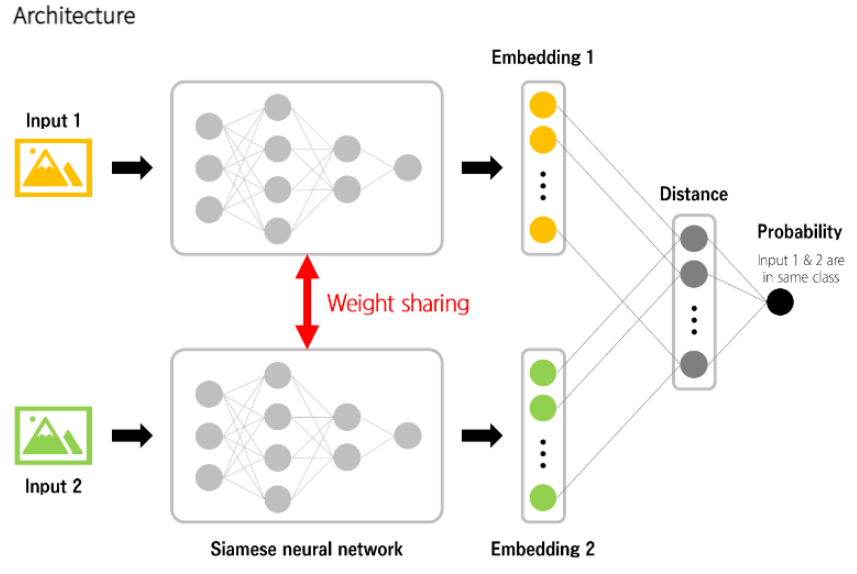

In [26]:
# input1, 2 -> 비교, 판단할 대상
# siamese neural network -> 두 입력에 같은 가중치를 적용, 공유
# embedding 1, 2 -> 각 입력으로부터 나온 임베딩 벡터
# distance -> 두 임베딩 벡터 간 거리 계산(유클리디언 거리, 코사인 유사도 등,,)
# 거리가 짧으면 비슷하다 -> 같은 클래스일 확률 / 거리가 멀면 다르다 -> 같은 클래스일 확률 낮음
# probability -> 거리를 바탕으로 확률값 반환
# 결론 : 모든 학습 데이터에 대한 임베딩 값을 계산해서 같은 클래스끼리는 모이고, 다른 클래스 끼리는 멀어지는 결과를 만듦

In [32]:
from sentence_transformers import SentenceTransformer

model2 = SentenceTransformer("snunlp/KR-SBERT-V40K-klueNLI-augSTS")

sentences = [
    "그 식당은 파리를 날린다",
    "그 식당에는 손님이 없다",
    "그 식당에서는 드론을 날린다",
    "파리가 식당에 날아다닌다"
]
embeddings = model2.encode(sentences)

similarities = model2.similarity(embeddings, embeddings)
print(similarities.shape)

torch.Size([4, 4])


In [33]:
similarities[0]

# 0번 문장과 다른 문장의 유사도 점수

tensor([1.0000, 0.6306, 0.4713, 0.8197])

In [31]:
similarities[1]

# 1번 문장과 다른 문장의 유사도 점수

# 인덱스 번호에 해당하는 숫자값이 1인 이유는?
# 같은 문장이므로 당연히 1



tensor([0.6306, 1.0000, 0.3379, 0.4095])

### 토픽 모델링(BERTopic 적용)
- 여러 문서에서 숨겨진 주제나 토픽을 찾아내는 텍스트 마이닝 기법
- 문서들을 분석해서 어떤 주제들이 포함되어 있는지, 각 문서가 어떤 주제와 연관되어있는지를 파악하는데 활용
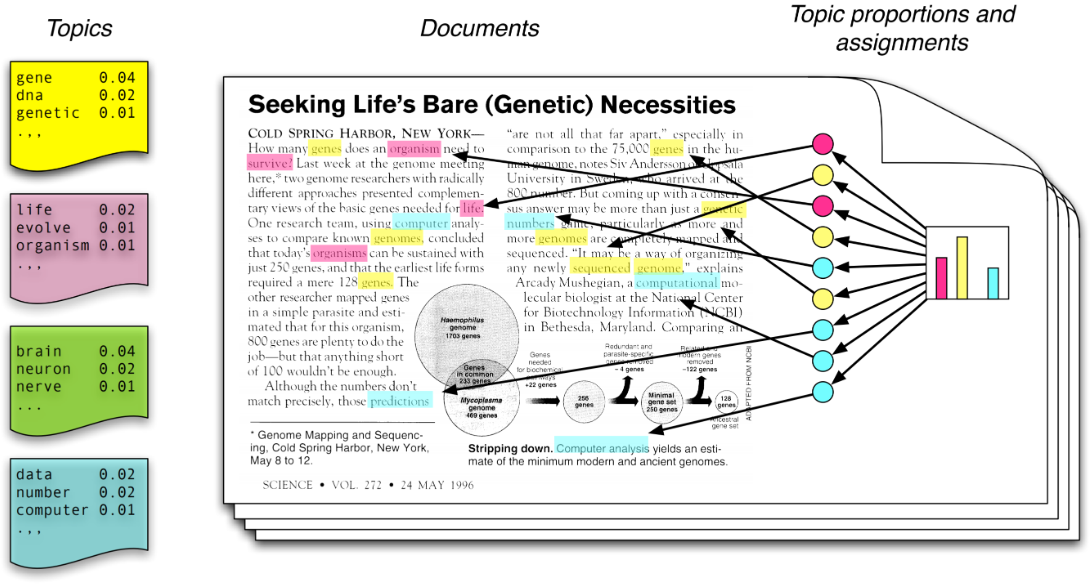

### BERTopic
- Transformer 기반 임베딩과 군집화 기법을 결합한 토픽 모델링 기법
- 임베딩된 문서를 UMAP(차원 축소 알고리즘)으로 차원 축소 후, HDBSCAN(또는 KMeans)으로 클러스터링 수행
- 각 클러스터의 대표 키워드를 추출하고 토픽 해석에 용이
- 전통적 LDA처럼 단어 빈도만 보는게 아니라, 문장/문서간 의미적 유사성을 반영
  - LDA(Latent Dirichlet Allocation)
    - 자연어처리에서 문서에 내재된 주제를 파악하는 확률적 토픽 모델링 기법
    - 빈도수만을 활용하며, 토픽의 개수를 주제 일관성(coherence) & 혼란도(perplexity) 등을 활용해서 수동 설정이 필요

#### 주요 구성요소
- 문서 임베딩 : SBERT, 입력된 문서 768차원 이상의 실수 벡터로 변환, 의미론적 유사성을 벡터간의 거리로 표현
- 차원 축소 : UMAP, 고차원 임베딩을 2~5차원 정도로 줄여 계산/시각화 효율 개선, 유사한 벡터는 가깝게, 먼 벡터는 멀게 배치
- 밀도기반 군집화(HDBSCAN) : UMAP으로 축소된 벡터 공간에서 "문서 간 밀도 차이"를 이용해서 클러스터(토픽) 수를 자동 판단, 노이즈(어떤 클러스터에도 속하지 않는 문서)도 함께 걸러냄
- 토픽 키워드 생성(c-TF-IDF, class-based TF-IDF) : 클러스터별로 속한 문서들을 하나의 가상 문서(corpus)로 보고 그 내부에서 TF-IDF를 계산해서 "해당 토픽을 대표하는 키워드" 추출

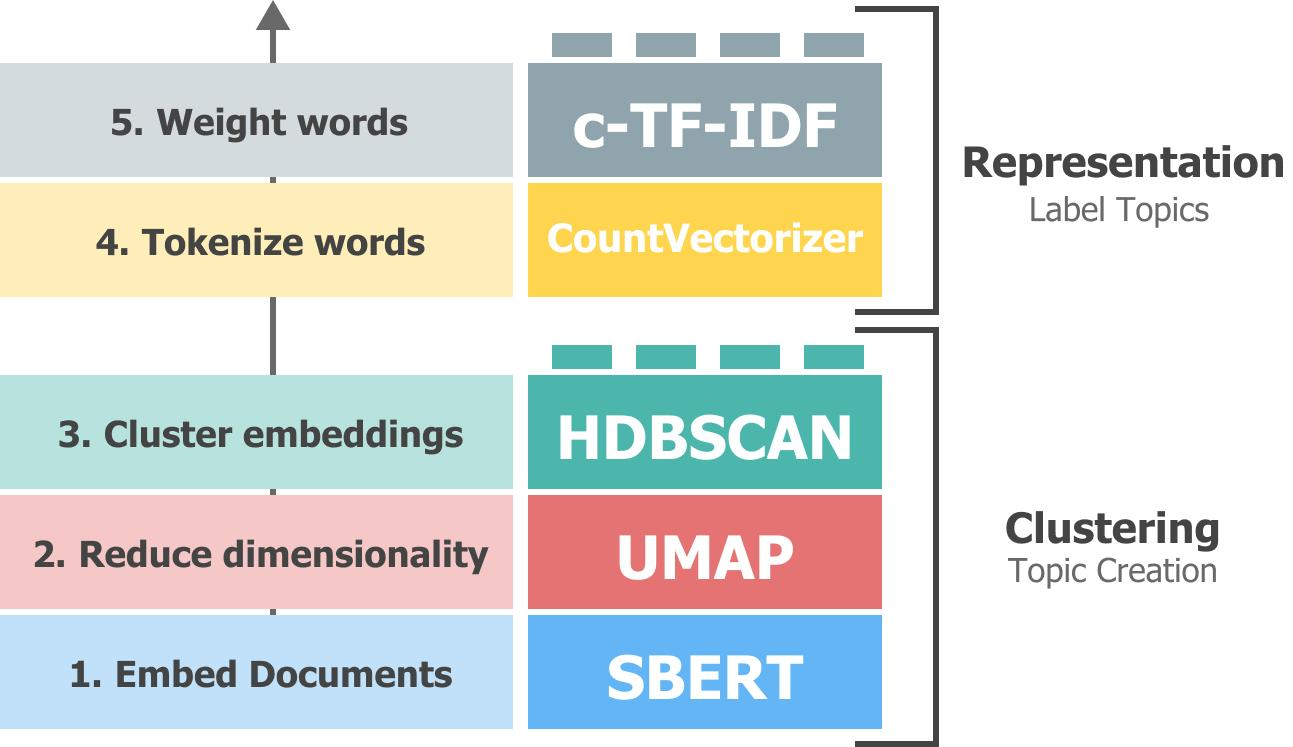


- 장점
  - 의미 기반 토픽 추출 : LDA 대비 더 정교
  - 토픽 수 자동 결정 및 노이즈 필터링
  - 다양한 언어, 도메인에 쉽게 적용 가능
- 단점 및 주의사항
  - 파라미터 민감도 : UMAP, HDBSCAN 튜닝이 필요
  - 대규모 데이터에서 메모리 사용량, 시간 부담
  - 임베딩 모델 선택에 따라 성능 차이

In [ ]:
# 원문 / 요약문 기반 토픽 모델링 진행
# SBERT, 원문데이터, 요약데이터

In [3]:
import os, json, re

train_dir = './data/Korean_SNS/Training/' # 약 36만건
val_dir = './data/Korean_SNS/Validation/' # 약 4만 5천건

# 라벨별로 200개만 사용하기 위해 제한
limit_per_label = 200

from tqdm.auto import tqdm # 반복문 진행 정도를 시각적으로 파악할 수 있게 해주는 도구

# 모든 json 데이터 불러오는 함수
def load_and_normalize(dir_path):
  """
  dir_path 내 모든 json 파일을 순회하면서 각 대화의 발화(utterance)를 하나의 문서(text)로 연결하는 함수
  parameter(dir_path) : str (json 파일들의 경로)
  return(corpus) : list (대화가 병합된 텍스트 리스트)
  """
  corpus = [] # 결과를 담을 리스트
  for fname in tqdm(os.listdir(dir_path), desc=f"Loading {dir_path}"):
    # 해당 폴더내 모든 파일의 이름을 가져와서 반복
    file_path = os.path.join(dir_path,fname)
    count = 0 # 라벨당 문서수 카운터 초기화

    with open(file_path,'r',encoding='utf-8') as f:
      dataset = json.load(f)

    for dialog in tqdm(dataset['data'],desc=f'전처리중 {fname}'):
      if count>= limit_per_label:
        # 라벨당 제한 초과 시 반복 종료
        break

      text = " ".join(body['utterance'] for body in dialog['body'])
      # 각 발화(body)의 'utterance'필드만 추출하여 공백으로 연결

      corpus.append(text) # 리스트 추가
      count += 1 # 문서 카운트 증가

  return corpus

# 학습 및 검증 데이터셋 로드
train_corpus = load_and_normalize(train_dir)
val_corpus = load_and_normalize(val_dir)

# 원본데이터 불러오는 코드
############################################################
# SBERT 불러오는 코드

from sentence_transformers import SentenceTransformer

model2 = SentenceTransformer("snunlp/KR-SBERT-V40K-klueNLI-augSTS")

Loading ./data/Korean_SNS/Training/:   0%|          | 0/3 [00:00<?, ?it/s]

전처리중 미용과건강.json:   0%|          | 0/99383 [00:00<?, ?it/s]

전처리중 식음료.json:   0%|          | 0/146620 [00:00<?, ?it/s]

전처리중 일과직업.json:   0%|          | 0/107976 [00:00<?, ?it/s]

Loading ./data/Korean_SNS/Validation/:   0%|          | 0/3 [00:00<?, ?it/s]

전처리중 일과직업.json:   0%|          | 0/13498 [00:00<?, ?it/s]

... (13 outputs left out)

vocab.txt:   0%|          | 0.00/336k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/967k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

In [5]:
len(train_corpus)

600

In [6]:
# BERTopic 설치
!pip install -q bertopic

In [7]:
from bertopic import BERTopic

In [47]:
# 원문 기반 BERTopic 초기화
topic_model_orig = BERTopic(
    embedding_model=model2, # SBERT 임베딩 모델명
    calculate_probabilities=True, # 문서별 각 토픽에 해당하는 확률 계산
    verbose=True # 학습 과정 로그 출력
)

In [49]:
# 원문 기반 토픽 모델링 수행
topics_orig, probs_orig = topic_model_orig.fit_transform(train_corpus)


2026-11-26 06:47:58,401 - BERTopic - Embedding - Transforming documents to embeddings.


Batches:   0%|          | 0/19 [00:00<?, ?it/s]

2026-11-26 06:50:26,680 - BERTopic - Embedding - Completed ✓
2026-11-26 06:50:26,681 - BERTopic - Dimensionality - Fitting the dimensionality reduction algorithm
2026-11-26 06:50:27,619 - BERTopic - Dimensionality - Completed ✓
2026-11-26 06:50:27,621 - BERTopic - Cluster - Start clustering the reduced embeddings
2026-11-26 06:50:27,654 - BERTopic - Cluster - Completed ✓
2026-11-26 06:50:27,659 - BERTopic - Representation - Fine-tuning topics using representation models.
2026-11-26 06:50:27,711 - BERTopic - Representation - Completed ✓


In [10]:
print(topics_orig) # 문서별 할당된 토픽 번호 출력 (-1 : Noise)
print(probs_orig) # 문서가 토픽 n에 속할 확률

[0, 0, -1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, -1, 0, 0, 0, 0, 0, -1, 0, 0, 0, 0, 0, 0, -1, 0, 0, 0, 1, 1, 0, 0, 0, 0, 1, 0, 0, 0, -1, 1, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 1, 0, 0, 0, -1, 0, 0, 0, -1, 0, 0, -1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, -1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 1, 1, -1, -1, 0, 0, -1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, -1, 0, 0, -1, 0, -1, 0, 0, 1, 0, -1, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, -1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, -1, 1, 1, 1, 1, 1, -1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,

In [13]:
# 토픽 정보 확인
info_orig = topic_model_orig.get_topic_info()
info_orig

# Topic : 토픽 id
# Count : 해당 토픽에 할당된 문서 개수
# Name : <토픽번호>_<대표 키워드 조합>
# Representation : C-TF-IDF로 추출한 토픽별 상위 키워드 리스트
# Representative_Docs : 해당 토픽을 대표하는 문서(대) 샘플 리스트

,Topic,Count,Name,Representation,Representative_Docs
0,-1,39,-1_이름_ㅋㅋㅋ_근데_오늘,"[이름, ㅋㅋㅋ, 근데, 오늘, 진짜, ㅎㅎ, ㅋㅋㅋㅋㅋㅋㅋㅋㅋ, ㅋㅋㅋㅋ, 아직,...",[오늘 괄사치료 예약할 수 있나요? #@이름#선생님 다른 분 예약되어 있는데 그 ...
1,0,349,0_근데_이름_진짜_ㅠㅠ,"[근데, 이름, 진짜, ㅠㅠ, ㅋㅋㅋ, ㅋㅋ, 그냥, 그럼, 지금, 이모티콘]",[그 전달사항 2개있어요. 1. 어제 #@이름#님이 언제 결과 나오냐고 물어보셔서 ...
2,1,212,1_이름_시스템_사진_이모티콘,"[이름, 시스템, 사진, 이모티콘, ㅋㅋ, ㅋㅋㅋ, 오늘, ㅋㅋㅋㅋ, 그냥, 내가]",[오늘도 엄청 바빴구나 #@이름#이 고생했어ㅠㅠ 나는 저녁 쉐이크 먹었어!!!! 맛...


In [16]:
# 요약문 기반 토픽 모델링 수행

# 요약문 불러오기
import pickle
with open('data/summary.pkl', 'rb') as f:
  summaries = pickle.load(f)
len(summaries)

600

In [18]:
train_corpus[0]

'마니아프세여??? #@시스템#사진# 흙흙흙 아 개피곤 ㅋㅋ 님 괜찮아여? 왜 먹고 먹고 머고만 햇는데 몸이 무겁지 걸은것도 별로 없는데 몰라여 응가싸서 그런가 고되다 똥싸서 몸무게 빠졋나 아삐건해 미틴ㅋㅋㅋㅋㅋㅋ 진짜 7-800그람 빠짐 나 몸이 너무 무거워서 몸무게 쟀는데 빠져서 놀랏어 너무 무서워'

In [19]:
summaries[0]

'응가싸서 그런가 고되다 똥싸서 몸무게 빠졋나 아삐건해 미틴ᄏᄏᄏ  진짜 7-800그람 빠짐 나 몸이 너무 무거워서 쟀는데 빠져서 놀랏어 너무 무서워 너무 무서워서 놀랏어를 님 괜찮아여???'

In [22]:
topic_model_sum = BERTopic(
    embedding_model=model2, # SBERT 임베딩 모델명
    calculate_probabilities=True, # 문서별 각 토픽에 해당하는 확률 계산
    verbose=True # 학습 과정 로그 출력
)

In [23]:
topics_sum, probs_sum = topic_model_sum.fit_transform(summaries)

2026-11-26 05:54:56,017 - BERTopic - Embedding - Transforming documents to embeddings.


Batches:   0%|          | 0/19 [00:00<?, ?it/s]

2026-11-26 05:56:33,719 - BERTopic - Embedding - Completed ✓
2026-11-26 05:56:33,721 - BERTopic - Dimensionality - Fitting the dimensionality reduction algorithm
2026-11-26 05:56:34,656 - BERTopic - Dimensionality - Completed ✓
2026-11-26 05:56:34,657 - BERTopic - Cluster - Start clustering the reduced embeddings
2026-11-26 05:56:34,684 - BERTopic - Cluster - Completed ✓
2026-11-26 05:56:34,688 - BERTopic - Representation - Fine-tuning topics using representation models.
2026-11-26 05:56:34,723 - BERTopic - Representation - Completed ✓


In [24]:
info_sum = topic_model_sum.get_topic_info()
info_sum

,Topic,Count,Name,Representation,Representative_Docs
0,-1,163,-1_진짜_이제_한창_이렇게,"[진짜, 이제, 한창, 이렇게, 오늘, 근데, ᄏᄏᄏ, 이름, 아니, 사진]",[신세계임 진짜 진짜 공부하면서 시력 나가리된듯 셤치고 수술하자 끼고 있는안경도...
1,0,173,0_이름_시스템_이거_이모티콘,"[이름, 시스템, 이거, 이모티콘, 사진, ᄏᄏᄏ, 오늘, 내가, 많이, 내일]",[이게 나오면 나오면 대부분1차 단계여서 고위험군 아니먼 약물하면된뎅 쩝스바리 면역...
2,1,74,1_ᄏᄏᄏ_ᄏᄏ_옛날_혼자,"[ᄏᄏᄏ, ᄏᄏ, 옛날, 혼자, 옛날에, 이름, 이모티콘, 매일, 엄마, 빨리]",[건강좋아 백미만은 별로 좋지 않아 응 참고할게요 #@이모티콘# 백미는 이러저런 영...
3,2,70,2_진짜_하면_응응_이름,"[진짜, 하면, 응응, 이름, 아직도, 근데, ᄏᄏᄏ, 너무, 그니까, 계속]",[메일에 목적이 없긴한데 쓸말이 너무 없어 ᄏᄏᄏ 그냥 그냥 졸업햇잖아 뭐 감사하...
4,3,63,3_너무_진짜_나도_운동,"[너무, 진짜, 나도, 운동, 그냥, 이름, 아픈, 아직, 근데, 병원]",[나도 첨에 눈 넘 아팠을 때 무서웠음 나도 비슷한 적 있어서 알아 아프지 말자 헷...
5,4,36,4_일찍_오늘부터_누적_면회가,"[일찍, 오늘부터, 누적, 면회가, 직원, 주말에, 오늘, 직장, 화욜, 피곤하네]","[월욜누적목표매출에 이거 입력해서 밑으로 드래그 끌어=SUM($F3,C4) 억 쩐다..."
6,5,21,5_머리를_엄청_피지_바르고,"[머리를, 엄청, 피지, 바르고, 그냥, 그거, 여름에, 여드름, 두피, 앞머리]",[너 저 저번에 서현에서 받은 마사지 무슨 코스로 받았어? 음 잠만 아로마 포커스 ...


In [25]:
# 원문기반 vs 요약문 기반 토픽 모델링 결과가 차이가 나는 이유
# 요약문 기반 토픽이 상대적으로 정제된 키워드를 확인
# 불용어 감소, 중복 감소, 핵심 정보만 남음 -> 토픽 모델링 하기에 더 좋은 상태

In [26]:
# 토픽 분포 비교

# 토픽 비교용 데이터프레임 생성
import pandas as pd
df_topic_compare = pd.DataFrame({
    'original' : topics_orig,
    'summary' : topics_sum
})

df_topic_compare

,original,summary
0,0,3
1,0,0
2,-1,0
3,0,2
4,0,5
...,...,...
595,0,4
596,0,-1
597,0,1
598,0,2


In [42]:
# 원문 토픽별 문서수 집계 -> 인덱스(토픽ID) 기준으로 정렬
orig_topic_counts = df_topic_compare['original'].value_counts(). sort_index()
orig_topic_counts

,count
original,
-1,39
0,349
1,212


In [43]:
# 요약문 토픽별 문서수 집계 -> 인덱스(토픽ID) 기준으로 정렬
sum_topic_counts = df_topic_compare['summary'].value_counts(). sort_index()
sum_topic_counts

,count
summary,
-1,163
0,173
1,74
2,70
3,63
4,36
5,21


In [41]:
# 하나의 데이터 프레임으로 만들기
df_topic_counts = pd.concat([orig_topic_counts, sum_topic_counts],
          axis=1, # 열 방향으로 합치기
          keys = ['origin_count', 'sum_count'] # 새로운 컬럼명 지정
          ).fillna(0) # NaN을 0으로 채우기

df_topic_counts

,origin_count,sum_count
-1,39.0,163
0,349.0,173
1,212.0,74
2,0.0,70
3,0.0,63
4,0.0,36
5,0.0,21


<Figure size 1000x500 with 0 Axes>

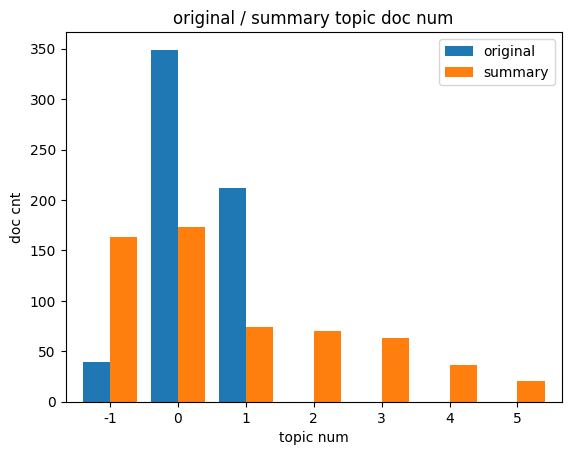

In [44]:
import matplotlib.pyplot as plt
# 시각화
plt.figure(figsize=(10,5))

# 판다스의 데이터프레임도 시각화 함수가 있음!
df_topic_counts.plot(kind='bar',width=0.8)
# plt.bar(df_topic_counts.index, df_topic_counts['origin_count])

plt.title('original / summary topic doc num') # 원문 / 요약 토픽별 문서 분포
plt.xlabel('topic num') # 토픽 번호
plt.ylabel('doc cnt') # 문서 수
plt.xticks(rotation=0) # x축 눈금 레이블 각도 0도 설정(안하면 숫자 꺾여있음)
plt.legend(['original','summary'])
plt.show()

In [45]:
# 그래프 해석
# 원문 / 요약문 비교
# 요약문 토픽 모델링에서 노이즈(-1) 토픽 증가
# 이유는? 요약 과정에서 맥락이 충분하지 못한 문서들이 노이즈로 분류
# 요약하면서 불필요한 대화, 중복 발화가 제거 되면서 주제 식별이 어려운 문서가 더 많아진 것으로 보임

In [50]:
# 대표문장을 확인해보자
for t in range(0,2):
  print(f' 토픽 번호 : {t}')
  # 원문과 요약에서 토픽 t의 상위 키워드 5개 추출
  print('원문 키워드 :', [w for w,_ in topic_model_orig.get_topic(t)[:5]])
  print('요약 키워드 :', [w for w,_ in topic_model_sum.get_topic(t)[:5]])
  # 원문과 요약에서 토픽 t를 대표하는 상위 2개의 문장
  print('원문 대표문장 :', topic_model_orig.get_representative_docs(t)[:2])
  print('요약 대표문장 :', topic_model_sum.get_representative_docs(t)[:2])


 토픽 번호 : 0
원문 키워드 : ['근데', '이름', '진짜', 'ㅠㅠ', 'ㅋㅋㅋ']
요약 키워드 : ['이름', '시스템', '이거', '이모티콘', '사진']
원문 대표문장 : ['#@이름#아 떙이돌 오늘 받으러 가 근데 땡이돌 건조하대 그래서 여름에 좋나봐 나는 뭐 상관없지만.. 근데 또 뭐 여러개 바르면 괜찮은거 같아 마자 여름에 발랐을 때 내가 너네한테 건조하다고 했어 근데 크림을 하나 덜 바르고 발랐던거라서 그랬을 수 있고 아 고터까지가기 귀차나..ㅠㅠ 갓는데 색도 이상한거주면억케... 가서 너는 bo01해도 될거 같아 옐로베이스야 너 원래 옐로 베이스 쓰잖아 그지? 그니까 가서 저 혹시 bo01로 주시면 안될까여... 하면 주지 않을까 어차피 그게 주력 컬러던데 그게 색별로 잇으려나.. 주력컬러는 있을걸', '근데 내가 강남병원 갔잖아 근데 수포가 올라오면 주는게 맞긴 한데 그 할아버지 의사도 스프레이 처방해달라고 하나 하니깐, 금방 나을껀대 비싸게 그건 왜 하냐고 #@이름# 심하지 않아 그런거 아냐 난 #@이름# 전날 밤새 한숨도 안자고 오열해서 그 아침에 스프레이 뿌리면 그래도 물 마시고 다시 자고 그러더라고 근데 #@이름# 지금까지 구내염 3번인대 스프레이는 너한테 처음 들었어 스프레이가 탄툼이자나 그 헥사메딘이랑 비슷한거거든 그동안 갔던 모든 병원 안줬어 어른은 가글을 할수있는데 애들은 가글 안하니까 그게 필수는 아냐 #@이름#  스프레이 싫어해서 뿌리지도 못함 ㅋ 그냥 통증을 잠시 완화 시키는거지 뭐 암튼 난 그냥 꿈이든 돌고래 다닐래... 난 그냥 기침약 잘 받아서 거기간다 ㅋㅋㅋㅋㅋㅋㅋㅋ 그래 ㅋㅋㅋㅋ']
요약 대표문장 : ['이게 나오면 나오면 대부분1차 단계여서 고위험군 아니먼 약물하면된뎅 쩝스바리 면역력관리잘해야한뎅 그래도 좀그렇잔ᄅ아 찜찜라지 걱정이군 질염정도일줄알았는데 이게 나오면 이거 나오면 이거 이거 이거 나온 이거 이거 나오 근데 이거 이거 나오는 이거 이거 이걸 이거 이거 나오면 이걸 이거 나오면 이게 나오면 이

In [51]:
# 토픽별 원문 / 요약문 비교 분석
# 0번 토픽 : 업무 관련 대화 -> 음식 대화로 재편
# 1번 토픽 : 다이어트 관련 대화 -> 업무 관련 대화 재편성
# 2번 토픽 : 치아, 건강..
# 3번 토픽 : 음식 대화
# 4번 토픽 : 실적, 건
# 5번 토픽 : 미용 관련 대화

In [52]:
# 종합 정리
# 요약 후 추가 정제가 아직은 더 필요해 보임 -> 의미없는 표현이 아직은 많이 남아있음
# 키워드만 봤을때, 원문 토픽은 주제 구분이 모호함, 요약 후 토픽은 좀 더 보이긴 함
# 요약 모델의 반복 생성 문제 -> 반복이 계속 발생해서 토픽 해석 신뢰도가 떨어져 보임

In [55]:
# 파이프라인 예시
# 새 문서가 들어오면 "요약 -> 임베딩 -> 클러스터링(BERTopic) -> (감성분석, 현재는 생략)"의 결과를 한번에 도출하는 함수


In [56]:
def analyze(docs):
  # 1. 요약
  # summarize : 우리가 선언(정의)한 요약을 하는 함수
  # 요약 모델을 선언한 상태여야 실행 가능!
  sums = [summarize(d) for d in docs]

  # 2. 토픽모델링(BERTopic)
  # 임베딩 -> 클러스터링
  new_topics, _ = topic_model_sum.transform(sums)
  # 이미 학습된 모델에 새 문서를 넣을 때는 transform을 활용
  # - : 변수 지정 안하고 사용(현재 이 자리는 확률값)

  # 3. 감성분석 모델(있다면 추가)

  # 4. 결과 변환
  return pd.DataFrame({
      '원문' : [d for d in docs],
      '요약' : sums,
      '토픽' : new_topics
  })

In [ ]:
# 우리가 수행한 작업 : 사전학습된 모델을 활용해서 여러 작업을 수행
# 특별한 학습과정이 없어서 편리하긴 하지만, 결과는 썩...
# 보다 정확한 결과를 얻기 위해서는 주제에 맞게 파인튜닝된 모델이 있는 편이 좋음

# 기본 구조를 익히고, 파인튜닝 방법을 진행해보자